# Circles around a location

In [1]:
import cartopy.crs as ccrs
import earthkit.plots as ekp
import numpy as np

from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import circle, circle_quadrants, polyline_normals

## What ``circle`` returns

The function returns two arrays: the latitudes and the longitudes (in degrees) of ``n`` points
(default 100). The rules are:

- The radius is the distance along the surface of the sphere (the great circle distance), not the
  straight line distance through the Earth. Only the radius of the ``figure`` is used.
- The circle is closed: the last point is an exact copy of the first one.
- The first point is due north of the centre and the points go clockwise seen from above: north,
  east, south, west. The bearings of the ``n - 1`` distinct points are ``360 * j / (n - 1)`` degrees.

Here are the 5 points at 1000 km around the point (0, 0). The longitude of the centre is
non-negative, so the result is in [0, 360) and the western point is at 351.0°.

In [2]:
lats, lons = circle(0, 0, 1000, n=5)
print("lats:", np.round(lats, 4) + 0.0)
print("lons:", np.round(lons, 4) + 0.0)

lats, lons = circle(51.45, -0.97, 250)  # Reading, UK
print("number of points:", lats.shape[0])
print("closed:", bool(lats[0] == lats[-1] and lons[0] == lons[-1]))

lats: [ 8.9929  0.     -8.9929  0.      8.9929]
lons: [  0.       8.9929   0.     351.0071   0.    ]
number of points: 100
closed: True


## Circles of a few radii around Reading

The same location with radii of 100, 250 and 500 km. The default ``n=100`` is dense enough to
look smooth on a map. The longitude of the centre is negative, so the longitudes are in
[-180, 180) and the circles plot continuously.

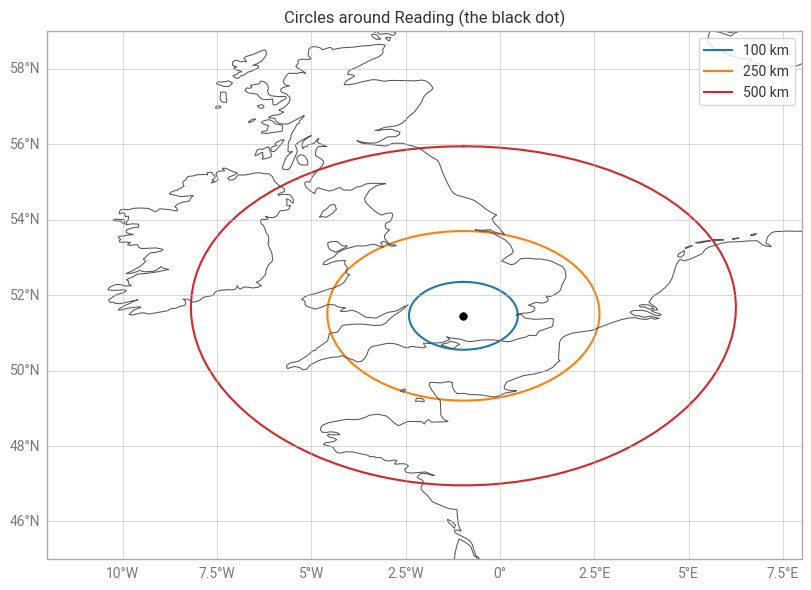

In [3]:
reading = (51.45, -0.97)
colours = {100: "tab:blue", 250: "tab:orange", 500: "tab:red"}

fig = ekp.Figure(rows=1, columns=1, figsize=(8, 6))
m = fig.add_map(domain=[-12, 8, 45, 59], crs=ccrs.PlateCarree())
for radius, colour in colours.items():
    lats, lons = circle(*reading, radius)
    m.line(lons, lats, label=f"{radius} km", color=colour, linewidth=1.5)
m.scatter([reading[1]], [reading[0]], color="k", s=30, zorder=5)
m.coastlines()
m.gridlines()
m.title("Circles around Reading (the black dot)")
m.legend()
fig.show()

## Crossing the dateline

The longitudes of all the points are returned in [0, 360) if the longitude of the centre is
non-negative and in [-180, 180) otherwise. A circle that crosses the dateline therefore jumps in
longitude when the centre is west of it. Giving the centre as 180.2° (the same place as -179.8°)
puts the result in [0, 360) and removes the jump.

centre -179.8: longitudes from -180.0 to 179.9
  largest step between neighbouring points: 359.8 degrees
centre 180.2:  longitudes from 177.4 to 183.0
  largest step between neighbouring points: 0.2 degrees


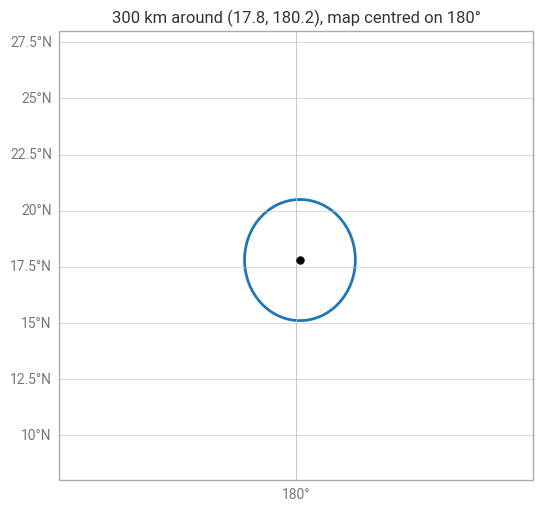

In [4]:
lats, lons = circle(17.8, -179.8, 300)  # centre west of the dateline
print(f"centre -179.8: longitudes from {lons.min():.1f} to {lons.max():.1f}")
print(f"  largest step between neighbouring points: {np.abs(np.diff(lons)).max():.1f} degrees")

lats, lons = circle(17.8, 180.2, 300)  # the same place, given as 180.2
print(f"centre 180.2:  longitudes from {lons.min():.1f} to {lons.max():.1f}")
print(f"  largest step between neighbouring points: {np.abs(np.diff(lons)).max():.1f} degrees")

fig = ekp.Figure(rows=1, columns=1, figsize=(7, 5))
m = fig.add_map(crs=ccrs.Robinson(central_longitude=180))
m.line(lons, lats, color="tab:blue", linewidth=2)
m.scatter([180.2], [17.8], color="k", s=30, zorder=5)
m.coastlines()
m.gridlines()
m.ax.set_extent([168, 192, 8, 28], crs=ccrs.PlateCarree())
m.title("300 km around (17.8, 180.2), map centred on 180°")
fig.show()

## Containing a pole

The circle may also contain a pole: the points are computed with vectors, so the result is
accurate there. The circle below is centred at (83, -40) with a radius of 1200 km; the pole is
about 780 km from the centre, so the outline wraps around it and its northernmost points come
back down on the other side. The black dot is the first point, due north of the centre, so it
lies past the pole on the meridian 140°E.

The line is drawn with ``transform=ccrs.Geodetic()``, so that the straight piece between two
neighbouring points follows the great circle. With the default transform (longitude and latitude
as plain coordinates) the pieces next to the pole, where the longitude changes quickly, are drawn
as straight lines in longitude and latitude and cut across the outline.

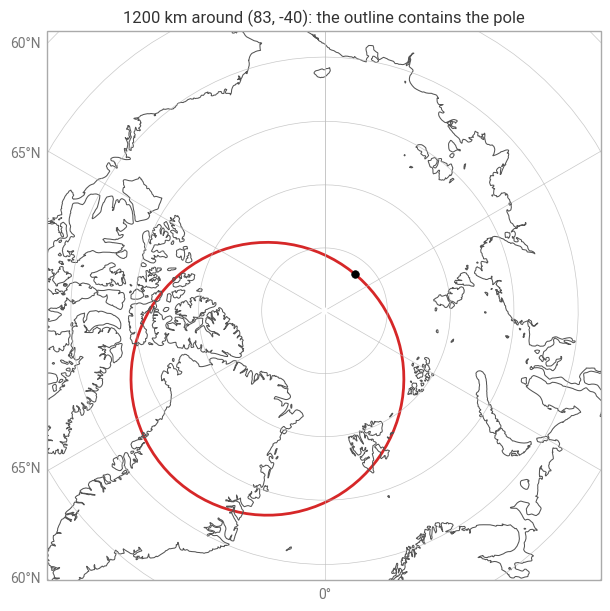

In [5]:
lats, lons = circle(83.0, -40.0, 1200)

fig = ekp.Figure(rows=1, columns=1, figsize=(6, 6))
m = fig.add_map(crs=ccrs.NorthPolarStereo())
m.line(lons, lats, color="tab:red", linewidth=2, transform=ccrs.Geodetic())
m.scatter([lons[0]], [lats[0]], color="k", s=30, zorder=5)
m.coastlines()
m.gridlines()
m.ax.set_extent([-180, 180, 68, 90], crs=ccrs.PlateCarree())
m.title("1200 km around (83, -40): the outline contains the pole")
fig.show()

## ``circle_quadrants``: a different radius in each quadrant

In [6]:
radii = [1000, 2000, 3000, 4000]  # north-east, south-east, south-west, north-west
lats, lons = circle_quadrants(0, 0, radii, n=9)
print("lats:", np.round(lats, 2))
print("lons:", np.round(lons, 2))

distance = [round(haversine_distance((la, lo), (0, 0)) / 1000) for la, lo in zip(lats, lons)]
print("distance from the centre (km):", distance)
print("the bearings are:              ", ["N", "E", "E", "S", "S", "W", "W", "N", "N"])

lats: [  8.99   0.     0.   -17.99 -26.98  -0.    -0.    35.97   8.99]
lons: [  0.     8.99  17.99   0.     0.   333.02 324.03   0.     0.  ]
distance from the centre (km): [1000, 1000, 2000, 2000, 3000, 3000, 4000, 4000, 1000]
the bearings are:               ['N', 'E', 'E', 'S', 'S', 'W', 'W', 'N', 'N']


## Example: a storm footprint

The radius of storm-force wind is often different in each quadrant around the centre. Four radii
around a storm in the North Atlantic give the footprint below. The dots are the points of the
outline and the steps are visible where the quadrants meet, due north, east, south and west. The
labels sit just outside the outline, at the middle bearing of each quadrant, found with
``circle`` again: with ``n=9`` its points are at the bearings 0, 45, 90 ... degrees.

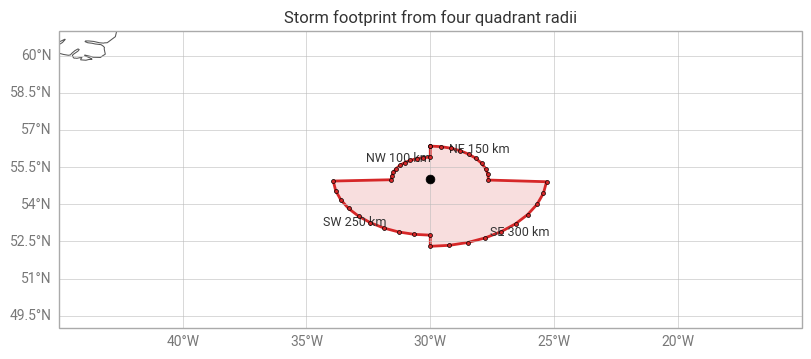

In [7]:
centre = (55.0, -30.0)  # storm centre
radii = [150, 300, 250, 100]  # km, north-east, south-east, south-west, north-west

lats, lons = circle_quadrants(*centre, radii, n=41)

fig = ekp.Figure(rows=1, columns=1, figsize=(8, 6))
m = fig.add_map(domain=[-45, -15, 49, 61], crs=ccrs.PlateCarree())
m.ax.fill(lons, lats, transform=ccrs.PlateCarree(), color="tab:red", alpha=0.15)
m.line(lons, lats, color="tab:red", linewidth=2)
m.scatter(lons, lats, color="tab:red", s=8, zorder=4)
for i, name in enumerate(["NE", "SE", "SW", "NW"]):
    la, lo = circle(*centre, 1.15 * radii[i], n=9)  # points at 0, 45, 90, ... degrees
    k = 2 * i + 1  # bearing 45, 135, 225 or 315 degrees
    m.text(float(lo[k]), float(la[k]), f"{name} {radii[i]} km", fontsize=9, ha="center")
m.scatter([centre[1]], [centre[0]], color="k", s=40, zorder=5)
m.coastlines()
m.gridlines()
m.title("Storm footprint from four quadrant radii")
fig.show()

## Outward normals

radial component of every normal: 0.9988 to 1.0000
all normals point outwards: True


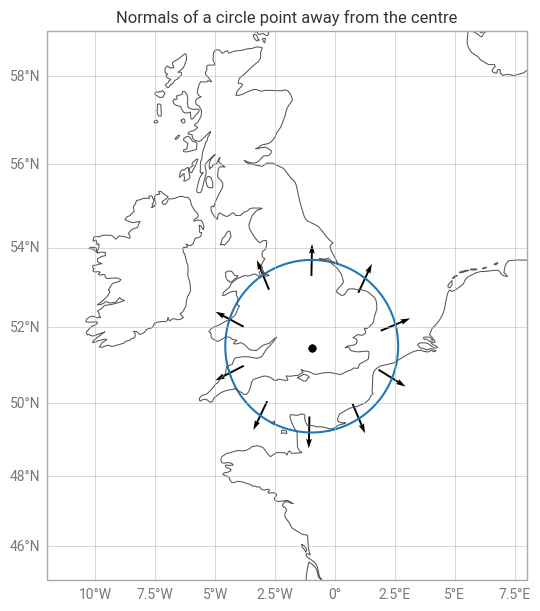

In [8]:
reading = (51.45, -0.97)
lats, lons = circle(*reading, 250)
east, north = polyline_normals(lats, lons)

bearings = np.deg2rad(360.0 * np.arange(len(lats)) / (len(lats) - 1))
radial = east * np.sin(bearings) + north * np.cos(bearings)
print("radial component of every normal:", f"{radial.min():.4f} to {radial.max():.4f}")
print("all normals point outwards:", bool(np.all(radial > 0)))

fig = ekp.Figure(rows=1, columns=1, figsize=(8, 6))
m = fig.add_map(domain=[-12, 8, 45, 59], crs=ccrs.Mercator())
m.line(lons, lats, color="tab:blue", linewidth=1.5)
m.quiver(
    x=lons[::10],
    y=lats[::10],
    u=east[::10],
    v=north[::10],
    resample=False,
    scale=15,
    width=0.004,
    color="k",
)
m.scatter([reading[1]], [reading[0]], color="k", s=30, zorder=5)
m.coastlines()
m.gridlines()
m.title("Normals of a circle point away from the centre")
fig.show()

## See also

- [Sampling points along a polyline](sample_polyline.ipynb): how to create the points of a polyline.
- [Normal vectors of a polyline](polyline_normals.ipynb): the normals used at the end of this notebook.
- [API reference](../../api-reference.rst): ``earthkit.geo.polyline.circle`` and
  ``earthkit.geo.polyline.circle_quadrants``.